In [1]:
%run general.ipynb
%matplotlib inline
RESULTS_DIR = '../results'
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f'Output directory: {RESULTS_DIR}')


/home/xuhuan/miniconda3/envs/qiime2-2022.2-my/lib/python3.8/site-packages/sklearn/utils/validation.py:70: FutureWarning: Pass n_repeats=1, random_state=None as keyword args. From version 1.0 (renaming of 0.25) passing these as positional arguments will result in an error
  warnings.warn(f"Pass {args_msg} as keyword args. From version "
/home/xuhuan/miniconda3/envs/qiime2-2022.2-my/lib/python3.8/site-packages/sklearn/utils/validation.py:70: FutureWarning: Pass n_splits=3, n_repeats=1 as keyword args. From version 1.0 (renaming of 0.25) passing these as positional arguments will result in an error
  warnings.warn(f"Pass {args_msg} as keyword args. From version "


2026-05-15 20:03:29 WARNING These have metadata but do not have data - dropped (415): {'BLANK.4.E7', 'H6.surface.10x.TE.03.17.16.glass.2', 'H3.skin.TE.09.14.15.3p.metal.2', 'BLANK8.7C', 'BLANK8.7F', 'BLANK8.8D', 'surface.ctrl.TE.09.14.15.4p.plastic.3', 'BLANK9.9F', 'BLANK.3.A3', 'BLANK6.6A', 'surface.ctrl.TE.09.14.15.4p.plastic.2', 'surface.ctrl.TE.09.14.15.11a.metal.5', 'BLANK13.5.5F', 'H5.skin.TE.09.14.15.3p.plastic.5', 'H4.skin.TE.09.14.15.11a.metal.1', 'surface.ctrl.9.12.17.plastic.1day.6', 'surface.ctrl.9.11.17.plastic.1sec.4', 'BLANK8.9H', 'BLANK8.3D', 'H3.skin.TE.09.14.15.11a.plastic.3', 'surface.ctrl.TE.09.14.15.11a.metal.3', 'H2.skin.TE.09.14.15.1p.metal.4', 'BLANK.2.D2', 'BLANK8.6G', 'H1.skin.TE.09.14.15.1p.glass.5', 'surface.ctrl.TE.09.14.15.3p.metal.2', 'BLANK8.6H', 'H10.skin.20x.9.15.17.plastic', 'ctrl.swab.3.201509', 'BLANK8.4F', 'surface.ctrl.TE.09.14.15.1p.glass.2', 'BLANK8.10B', 'BLANK13.3.3E', 'BLANK8.8G', 'H2.surface.20x.TE.12.17.15.plastic.3', 'H5.skin.TE.09.14.15.1

### Part 2: Individual Identification by **Touch Count**

This is an independent supplementary experiment exploring how touch count affects identification accuracy. 

In [2]:
exp_num_touches = exp.filter_samples('experiment_category', 'number_touches')
print(exp_num_touches)
print("\nSample type counts:")
exp_num_touches.sample_metadata.sample_type.value_counts()

AmpliconExperiment ("reference-hit.2026.biom") with 184 samples, 10511 features

Sample type counts:


sample_type
skin               105
surface_touched     60
surface_ctrl        14
swab                 3
blank                2
Name: count, dtype: int64

In [3]:
hosts_skin_touches_exp = set(exp_num_touches.sample_metadata.query('sample_type=="skin"')['individual'])
hosts_surface_touches_exp = set(exp_num_touches.sample_metadata.query('sample_type=="surface_touched"')['individual'])
common_hosts_touches_exp = list(hosts_skin_touches_exp.intersection(hosts_surface_touches_exp))
print(f"Common hosts for 'number of touches' experiment: {common_hosts_touches_exp}")

Common hosts for 'number of touches' experiment: ['H26', 'H23', 'H21', 'H13', 'H9', 'H29', 'H24', 'H4', 'H25', 'H1', 'H19', 'H12', 'H5', 'H30', 'H27', 'H28', 'H8', 'H22', 'H20', 'H16']


In [4]:
exp_num_touches.filter_samples('sample_type', 'skin').sample_metadata['individual'].value_counts()

individual
H19    6
H1     5
H13    5
H30    5
H12    5
H21    5
H4     5
H9     5
H22    5
H5     5
H39    5
H8     5
H28    5
H16    4
H25    4
H24    4
H40    4
H27    4
H38    4
H29    4
H23    4
H26    4
H20    3
Name: count, dtype: int64

In [5]:
train_set_touches = exp_num_touches.filter_samples('sample_type', "skin").filter_samples('individual', common_hosts_touches_exp).filter_by_metadata('_calour_original_abundance', select=lambda i: i > 500)
train_set_touches

AmpliconExperiment ("reference-hit.2026.biom") with 83 samples, 10511 features

In [6]:
test_set_touches = (exp_num_touches.filter_samples('sample_type', 'surface_touched')
                                   .filter_samples('individual', train_set_touches.sample_metadata.individual.unique().tolist())
                                   .filter_ids(train_set_touches.feature_metadata.index, axis=1)
                                   .sort_samples('individual')
                                   .sort_samples('touches'))
test_set_touches

AmpliconExperiment ("reference-hit.2026.biom") with 60 samples, 10511 features

In [7]:
train_sids_touches = train_set_touches.sample_metadata.index.values
test_sids_touches = test_set_touches.sample_metadata.index.values

In [8]:
grid_search_touches = make_rf_grid_search(rf_random_state=11, cv_random_state=1)


In [9]:
saved_model_path_touches = os.path.join(RESULTS_DIR, 'num-touches-model.pkl.bz2')
best_model_touches = load_or_fit_model(
    grid_search_touches, saved_model_path_touches,
    train_set_touches.data, train_set_touches.sample_metadata['individual']
)


Loading pre-trained model from ../results/num-touches-model.pkl.bz2...


In [10]:
jk_cache_path = os.path.join(RESULTS_DIR, 'num-touches-jackknife_fixed.pkl.bz2')
touch_order = ['10', '20', '30']
touch_to_i = {t: i for i, t in enumerate(touch_order)}

def touches_jk_contrib(md, subset_meta, **ctx):
    t_val = md['touches']
    if t_val not in touch_to_i:
        return []
    subset_counts = subset_meta['touches'].value_counts()
    return [{
        'group_index': touch_to_i[t_val],
        'target': md['individual'],
        'score_weight': 1.0 / subset_counts[t_val],
        'denom_weight': 0.0,
    }]

jackknife_results3 = compute_cached_jackknife_tensor(
    model=best_model_touches,
    X=test_set_touches.data,
    sample_metadata=test_set_touches.sample_metadata,
    contribution_getter=touches_jk_contrib,
    class_labels=best_model_touches.classes_,
    max_N=20,
    progress_every=50,
    tensor_shape=(len(touch_order),),
    normalize=False,
    cache_path=jk_cache_path,
    bar_key='jk3_bar',
    topn_key='jk3_topn',
    cache_extras={'touch_order': touch_order},
)

jk3_bar = jackknife_results3['jk3_bar']
jk3_topn = jackknife_results3['jk3_topn']
touch_order = jackknife_results3['touch_order']
max_N = jackknife_results3['max_N']

for t_i, t in enumerate(touch_order):
    accs_top20 = jk3_bar[19, :, t_i]
    print(f"touches={t}: Top-20 Acc = {accs_top20.mean():.4f}")


Loading cached jackknife results...
touches=10: Top-20 Acc = 1.0000
touches=20: Top-20 Acc = 1.0000
touches=30: Top-20 Acc = 1.0000


In [11]:
max_N_plot = 20
ns = np.arange(1, max_N_plot + 1)
plot_data_touches = []

touch_series = test_set_touches.sample_metadata['touches'].astype(str)
for t_idx, t_val in enumerate(touch_order):
    mask = (touch_series == str(t_val)).values
    touch_stats = compute_masked_jackknife_topn_stats(jk3_bar, mask, t_idx)
    plot_data_touches.append({
        'touches': t_val,
        'means': touch_stats['means'],
        'errors': touch_stats['se'],
        'top3_mean': touch_stats['means'][2],
        'top3_error': touch_stats['se'][2],
    })

init_plot_style()
palette = sns.light_palette('#1f77b4', n_colors=4)[1:]
markers = ['o', 'o', 'o']


In [12]:
def touch_auc_test(mask_A, mask_B, jk_data, t_idx_A, t_idx_B, alternative='greater'):
    """Perform an unpaired jackknife AUC test for two independent touches groups."""
    folds_A = extract_masked_fold_matrix(jk_data, mask_A, t_idx_A)
    folds_B = extract_masked_fold_matrix(jk_data, mask_B, t_idx_B)
    return jackknife_auc_unpaired_test(
        folds_A,
        folds_B,
        auc_divisor='max_N',
        alternative=alternative,
    )


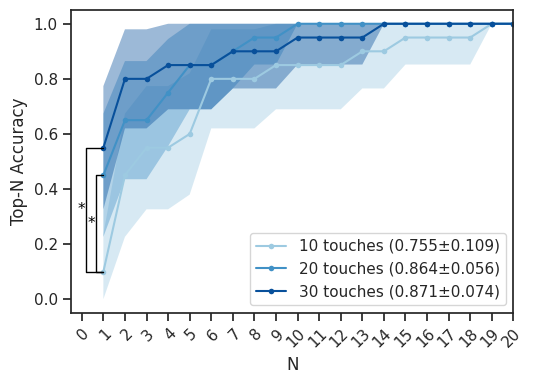

In [13]:
baseline_touch = '10'
touch_series = test_set_touches.sample_metadata['touches'].astype(str)

full_p = sns.color_palette('Blues', n_colors=len(touch_order) + 4)
palette = [full_p[2], full_p[4], full_p[6]]

fig_touches_err, ax_err, curves, bracket_info = plot_group_topn_jackknife(
    jk_topn=jk3_topn,
    sample_metadata=test_set_touches.sample_metadata,
    group_order=touch_order,
    axis_order=touch_order,
    metadata_col='touches',
    baseline_group=baseline_touch,
    color_dict=palette,
    marker=markers,
    figsize=(5.5, 4.0),
    group_values=touch_series.values,
    pvalue_fn=lambda **ctx: touch_auc_test(
        mask_A=ctx['group_mask'],
        mask_B=ctx['baseline_mask'],
        jk_data=ctx['jk_topn'],
        t_idx_A=ctx['group_index'],
        t_idx_B=ctx['baseline_index'],
        alternative='greater',
    ),
    label_fn=lambda t_val, _, __: f'{t_val} touches',
    alpha_fill=0.4,
    linewidth=1.5,
    markersize=4,
    legend_loc='lower right',
    x_anchor_index=0,
    xlim=(-0.5, max_N_plot),
    xticks=range(0, max_N_plot + 1),
    xlabel='N',
    ylabel='Top-N Accuracy',
    show=True,
)



In [14]:
d = RESULTS_DIR
save_fig(fig_touches_err, os.path.join(d, 'plastic-touch-number-top-N-with-error.pdf'))
print(f"Charts saved to: {d}")


Charts saved to: ../results


In [15]:
from skbio.stats.composition import clr
from math import ceil

/home/xuhuan/miniconda3/envs/qiime2-2022.2-my/lib/python3.8/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


H1 ['20', '30'] skin vs. touch 0.8954726112777301 0.0
H12 ['20', '30'] skin vs. touch 0.9118033212431783 0.0
H13 ['20', '30'] skin vs. touch 0.5471129080837449 0.0
H16 ['20', '30'] skin vs. touch 0.4774865116587823 0.0
H19 ['20', '30'] skin vs. touch 0.7861993302806163 0.0
H20 ['20', '30'] skin vs. touch 0.8878502566584711 0.0
H21 ['20', '30'] skin vs. touch 0.9274066646808551 0.0
H22 ['20', '30'] skin vs. touch 0.6294195260283555 0.0
H23 ['20', '30'] skin vs. touch 0.8064201783227722 0.0
H24 ['20', '30'] skin vs. touch 0.5854544160403806 0.0
H25 ['20', '30'] skin vs. touch 0.7966391702704229 0.0
H26 ['20', '30'] skin vs. touch 0.5352612897543294 0.0
H27 ['20', '30'] skin vs. touch 0.4814589857119734 0.0
H28 ['20', '30'] skin vs. touch -0.0008485133322737356 0.9306858637413673
H29 ['20', '30'] skin vs. touch 0.5161797212511245 0.0
H30 ['20', '30'] skin vs. touch 0.7378755416091248 0.0
H4 ['20', '30'] skin vs. touch 0.5944199684501298 0.0
H5 ['20', '30'] skin vs. touch 0.665331374209545

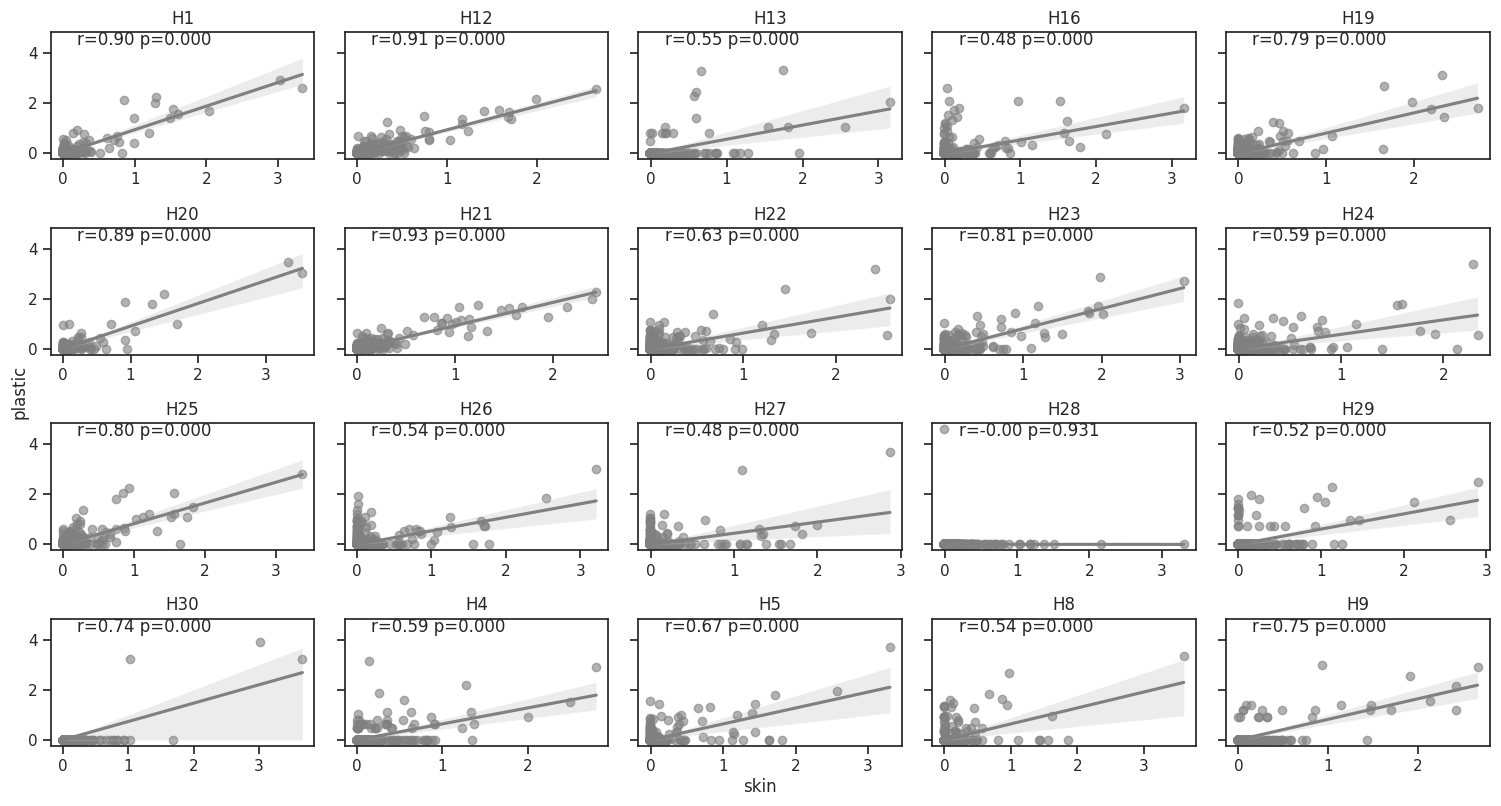

In [16]:
ncol=5
n = ['20', '30']
hosts = test_set_touches.filter_samples('touches', n).sample_metadata['individual'].unique()
fig, axarr = plt.subplots(ceil(len(hosts)/ncol), ncol, sharey=True, figsize=(15, 8))
for i, ind in enumerate(hosts):
    arr = train_set_touches.filter_samples('touches', 'skin').filter_samples('individual', ind).data
    ave = clr(arr.mean(axis=0).A1 + 1)
    for j, touches in enumerate([n]):
        touch = test_set_touches.filter_samples('touches', n).filter_samples('individual', ind).data[0]
        touch = clr(touch.todense().A1 +1)
        ax = axarr[i // ncol][i % ncol]
        ax.set_title(ind )
        sns.regplot(ave, touch, color='gray', scatter_kws={'alpha':0.6}, ax=ax)
        r, p = scipy.stats.pearsonr(ave, touch)
        print(ind, touches, 'skin vs. touch', r, p)
        ax.annotate("r={0:.2f} p={1:.3f}".format(r, p),
                    xy=(.1, .9), xycoords=ax.transAxes)
fig.text(0.5, 0.0, 'skin', ha='center')
fig.text(0.0, 0.5, 'plastic', va='center', rotation='vertical')
fig.tight_layout()

In [17]:
d = RESULTS_DIR
save_fig(fig, os.path.join(d, '201605.touches.number.skin-ave-vs-plastic.20x.clr.pdf'))

### various rarefy depth

In [19]:
exp_unnorm = ca.read_amplicon('../data/reference-hit.2026.biom', '../data/merged_mapping.txt',
                       normalize=None, min_reads=0, 
                       sample_metadata_kwargs=dict(na_values=['unknown'], dtype={'persistence_time_sec': str}))
exp_unnorm.data = exp_unnorm.data.astype('int')

2026-05-15 20:14:25 WARNING These have metadata but do not have data - dropped (415): {'BLANK.4.E7', 'H6.surface.10x.TE.03.17.16.glass.2', 'H3.skin.TE.09.14.15.3p.metal.2', 'BLANK8.7C', 'BLANK8.7F', 'BLANK8.8D', 'surface.ctrl.TE.09.14.15.4p.plastic.3', 'BLANK9.9F', 'BLANK.3.A3', 'BLANK6.6A', 'surface.ctrl.TE.09.14.15.4p.plastic.2', 'surface.ctrl.TE.09.14.15.11a.metal.5', 'BLANK13.5.5F', 'H5.skin.TE.09.14.15.3p.plastic.5', 'H4.skin.TE.09.14.15.11a.metal.1', 'surface.ctrl.9.12.17.plastic.1day.6', 'surface.ctrl.9.11.17.plastic.1sec.4', 'BLANK8.9H', 'BLANK8.3D', 'H3.skin.TE.09.14.15.11a.plastic.3', 'surface.ctrl.TE.09.14.15.11a.metal.3', 'H2.skin.TE.09.14.15.1p.metal.4', 'BLANK.2.D2', 'BLANK8.6G', 'H1.skin.TE.09.14.15.1p.glass.5', 'surface.ctrl.TE.09.14.15.3p.metal.2', 'BLANK8.6H', 'H10.skin.20x.9.15.17.plastic', 'ctrl.swab.3.201509', 'BLANK8.4F', 'surface.ctrl.TE.09.14.15.1p.glass.2', 'BLANK8.10B', 'BLANK13.3.3E', 'BLANK8.8G', 'H2.surface.20x.TE.12.17.15.plastic.3', 'H5.skin.TE.09.14.15.1

In [20]:
yhatall = []
for count in [10, 50, 100, 500, 1000, 2000]:
    for repeat in range(10):
        _exp = exp_unnorm.subsample_count(total=count, random_seed=repeat)
        _train = _exp.filter_ids(train_set_touches.sample_metadata.index, axis=0).filter_abundance(0, strict=True)
        _test = _exp.filter_ids(test_set_touches.sample_metadata.index, axis=0).filter_ids(_train.feature_metadata.index, axis=1).filter_samples('touches', '30')
        assert(np.all(train_set_touches.feature_metadata.index == test_set_touches.feature_metadata.index))
        rf = RandomForestClassifier(n_estimators=500)
        rf.fit(_train.data, _train.sample_metadata['individual'])
        yhat = rf.predict_proba(_test.data)
        _df = pd.DataFrame(yhat, columns=rf.classes_).rank(axis=1, ascending=False)
        _df['obs'] = _test.sample_metadata['individual'].values
        _df['depth'] = count
        _df['repeat'] = repeat
        yhatall.append(_df)
rare = pd.concat(yhatall, axis=0)

2026-05-15 20:14:28 WARNING 3 ids were not in the experiment and were dropped.
2026-05-15 20:14:32 WARNING 3 ids were not in the experiment and were dropped.
2026-05-15 20:14:35 WARNING 3 ids were not in the experiment and were dropped.
2026-05-15 20:14:38 WARNING 3 ids were not in the experiment and were dropped.
2026-05-15 20:14:42 WARNING 3 ids were not in the experiment and were dropped.
2026-05-15 20:14:45 WARNING 3 ids were not in the experiment and were dropped.
2026-05-15 20:14:48 WARNING 3 ids were not in the experiment and were dropped.
2026-05-15 20:14:51 WARNING 3 ids were not in the experiment and were dropped.
2026-05-15 20:14:54 WARNING 3 ids were not in the experiment and were dropped.
2026-05-15 20:14:58 WARNING 3 ids were not in the experiment and were dropped.
2026-05-15 20:15:01 WARNING 9 ids were not in the experiment and were dropped.
2026-05-15 20:15:04 WARNING 9 ids were not in the experiment and were dropped.
2026-05-15 20:15:07 WARNING 9 ids were not in the ex

In [21]:
d = RESULTS_DIR
rare_path = os.path.join(d, '201605.rarefy_train_test.pkl.gz')
if os.path.exists(rare_path):
    rare = pd.read_pickle(rare_path)
else:
    rare.to_pickle(rare_path)


In [22]:
def top_n_accuracy(df_rank, n=20):
    ranks = np.array([df_rank[h][i] for i, h in enumerate(df_rank['obs'])])
    rank_accu = np.array([np.sum(ranks <= i+1) for i in range(n)]) / df_rank.shape[0]
    return pd.DataFrame({'Top-N accuracy': rank_accu}, index=pd.Index(np.arange(1, n+1), name='N'))

In [23]:
rare_accuracy = rare.groupby(['depth', 'repeat']).apply(top_n_accuracy)
rare_accuracy.head()
rare_accuracy.reset_index(inplace=True)
rare_accuracy.head()

,depth,repeat,N,Top-N accuracy
0,10,0,1,0.235294
1,10,0,2,0.294118
2,10,0,3,0.352941
3,10,0,4,0.411765
4,10,0,5,0.529412


/tmp/ipykernel_60031/2841259648.py:29: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for handle in leg.legendHandles:


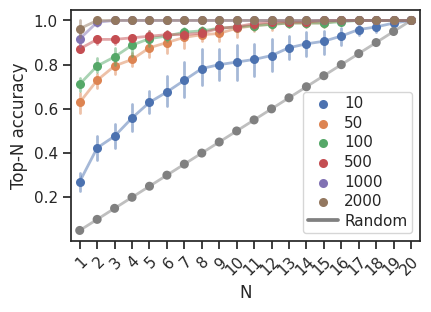

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
init_plot_style()
fig, ax = plt.subplots(figsize=(4.5, 3))

sns.pointplot(x='N', y='Top-N accuracy', hue='depth', data=rare_accuracy, ax=ax)

sns.pointplot(x=list(range(1, 21)), y=[i/20 for i in range(1, 21)], 
              color='gray', 
              ax=ax) 

handles, labels = ax.get_legend_handles_labels()
handles.append(ax.lines[-1])
labels.append('Random')

leg = ax.legend(handles=handles, labels=labels,
                labelspacing=0.3,    
                handletextpad=0.4,   
                borderpad=0.3)       

for l in ax.lines:
    l.set_alpha(.5)
    l.set_linewidth(2)  
    l.set_linestyle('-') 

for c in ax.collections:
    c.set_sizes([20])

for handle in leg.legendHandles:
    if hasattr(handle, 'set_sizes'):
        handle.set_sizes([20])  
    elif hasattr(handle, 'set_markersize'):
        handle.set_markersize(5)  
rotate_xticklabels(ax)

plt.show()

In [25]:
d = RESULTS_DIR
save_fig(fig, os.path.join(d, '201605.30x.rare-depths.pdf'))